# 🏠 Project 2: California House Price Prediction
**QSkill AI/ML Internship**

> **Note on Dataset Selection:** Earlier academic benchmarks frequently used the Boston Housing dataset. However, starting in `scikit-learn` v1.2, Boston was officially removed due to ethical and racial proxy biases. Following industry best practices, we use the **California Housing** dataset from the 1990 U.S. Census.

### Workflow Overview:
1. **Dataset Loading & Exploration:** Feature profiles and summary statistics.
2. **Exploratory Data Analysis (EDA):** Distributions, correlation matrix, price vs. income, and geographic mapping.
3. **Data Cleaning & Feature Engineering:** Domain-specific ratios and economic distance metrics.
4. **Modelling & 5-Fold Cross-Validation:** Comparing Linear, Ridge, Lasso, Random Forest, and Gradient Boosting regressors in clean leakage-free pipelines.
5. **Hyperparameter Tuning & Benchmark:** Optimizing the top-performing ensemble model.
6. **Model Diagnostics:** Actual vs. Predicted, Residual plots, and error analysis.
7. **Feature Importance & Model Limits:** Drivers of property valuation and known constraints.
8. **Serialization & Verification:** Saving the pipeline with `joblib` and testing inference.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-Learn tools
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    mean_squared_error, root_mean_squared_error,
    mean_absolute_error, r2_score
)

# Add project root to path for local src modules
nb_dir = os.path.dirname(os.path.abspath('__file__'))
proj_root = os.path.dirname(nb_dir) if 'notebooks' in nb_dir else os.path.abspath('.')
if proj_root not in sys.path:
    sys.path.insert(0, proj_root)

from src.data_loader import load_housing_data
from src.features import HousingFeatureEngineering, add_engineered_features

# Plot styles
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

## 1. Dataset Loading & Inspection

In [2]:
raw_df = load_housing_data()
print(f"Dataset Shape: {raw_df.shape}")
print(f"Missing values:\n{raw_df.isnull().sum()}")
raw_df.head()

Dataset Shape: (20640, 9)
Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# Summary statistics
raw_df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]

,count,mean,std,min,50%,max
MedInc,20640.0,3.870671,1.899822,0.499900,3.534800,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,29.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,5.229129,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.048780,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,1166.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.818116,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,34.260000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-118.490000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.797000,5.000010


## 2. Exploratory Data Analysis (EDA)

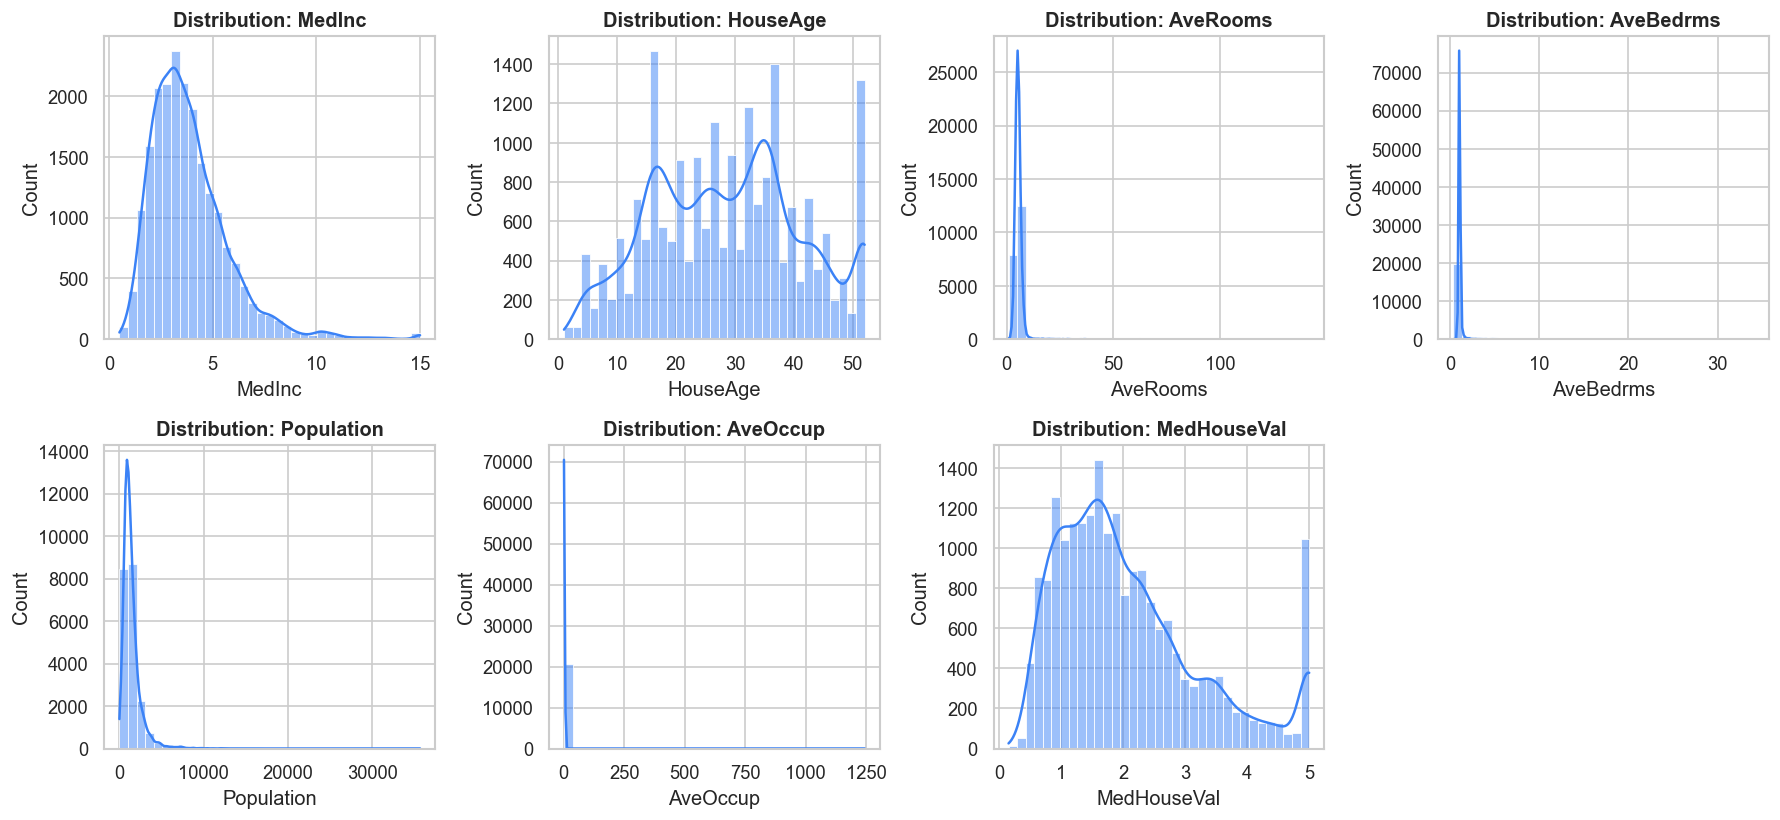

In [4]:
# Feature Distributions
features_to_plot = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'MedHouseVal']
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
axes = axes.flatten()
for i, col in enumerate(features_to_plot):
    sns.histplot(raw_df[col], kde=True, ax=axes[i], color='#3B82F6', bins=35)
    axes[i].set_title(f"Distribution: {col}", weight='bold')
fig.delaxes(axes[7])
plt.tight_layout()
plt.show()

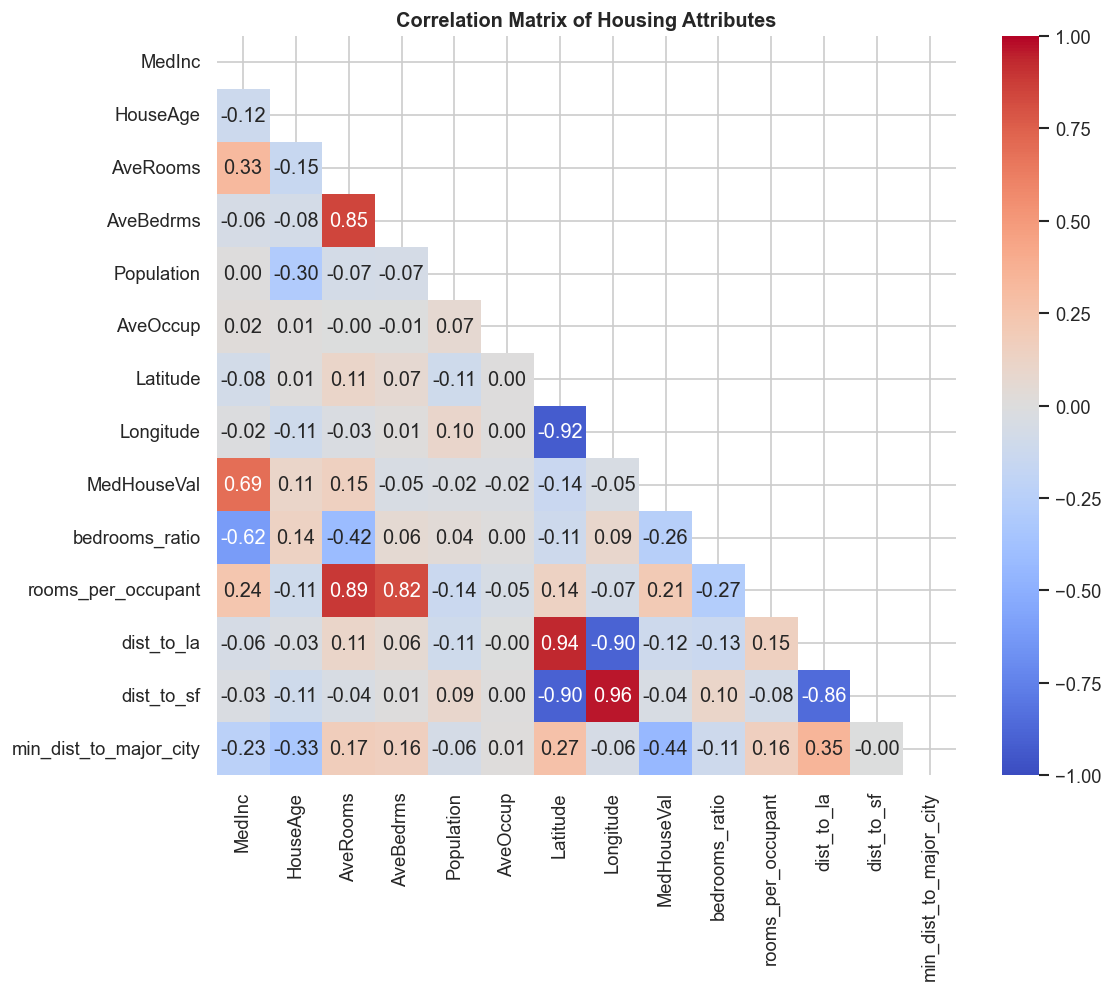

In [5]:
# Correlation Matrix with Engineered Features
df_eda = add_engineered_features(raw_df)
corr = df_eda.corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation Matrix of Housing Attributes', weight='bold')
plt.show()

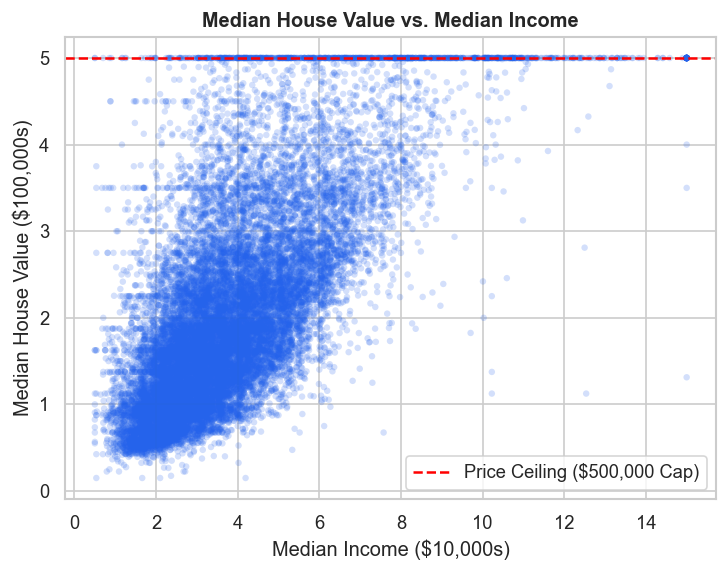

In [6]:
# Median Income vs. Price (highlighting the $500,000 ceiling cap)
plt.figure(figsize=(7, 5))
plt.scatter(raw_df['MedInc'], raw_df['MedHouseVal'], alpha=0.2, c='#2563EB', edgecolors='none', s=15)
plt.axhline(5.0, color='red', linestyle='--', lw=1.5, label='Price Ceiling ($500,000 Cap)')
plt.title('Median House Value vs. Median Income', weight='bold')
plt.xlabel('Median Income ($10,000s)')
plt.ylabel('Median House Value ($100,000s)')
plt.legend()
plt.show()

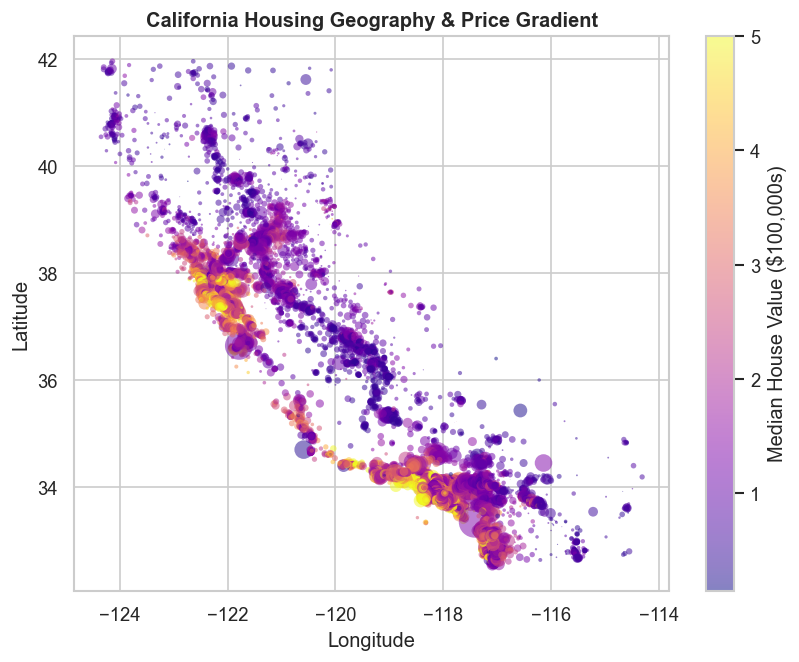

In [7]:
# Geographic Map (Lat/Long colored by Price, sized by Population)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    raw_df['Longitude'], raw_df['Latitude'],
    c=raw_df['MedHouseVal'], cmap='plasma',
    s=raw_df['Population'] / 100, alpha=0.5,
    edgecolors='none'
)
cbar = plt.colorbar(scatter)
cbar.set_label('Median House Value ($100,000s)')
plt.title('California Housing Geography & Price Gradient', weight='bold')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

## 3. Data Cleaning & Feature Engineering

In [8]:
# Outlier capping on extreme ratio artifacts for model stability
data = raw_df.copy()
data['AveRooms'] = np.clip(data['AveRooms'], 1.0, 20.0)
data['AveBedrms'] = np.clip(data['AveBedrms'], 0.5, 10.0)
data['AveOccup'] = np.clip(data['AveOccup'], 1.0, 20.0)
data['Population'] = np.clip(data['Population'], 1.0, 15000.0)

X = data.drop(columns=['MedHouseVal'])
y = data['MedHouseVal']

# 80/20 Train-Test Split (fixed random_state)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(f"Train size: {len(X_train)} | Test size: {len(X_test)}")

Train size: 16512 | Test size: 4128


## 4. Model Training & 5-Fold Cross-Validation

In [9]:
models = {
    'Linear Regression (Baseline)': (LinearRegression(), {}),
    'Ridge Regression': (Ridge(random_state=42), {'regressor__alpha': [0.1, 1.0, 10.0]}),
    'Lasso Regression': (Lasso(random_state=42, max_iter=3000), {'regressor__alpha': [0.001, 0.01, 0.1]}),
    'Random Forest Regressor': (RandomForestRegressor(random_state=42, n_jobs=-1), {'regressor__n_estimators': [100], 'regressor__max_depth': [20]}),
    'Gradient Boosting Regressor': (GradientBoostingRegressor(random_state=42), {'regressor__n_estimators': [200], 'regressor__learning_rate': [0.1], 'regressor__max_depth': [5]})
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
benchmark_results = []
trained_pipes = {}

for name, (reg, param_grid) in models.items():
    pipeline = Pipeline([
        ('feat_eng', HousingFeatureEngineering()),
        ('scaler', StandardScaler()),
        ('regressor', reg)
    ])
    
    if param_grid:
        grid = GridSearchCV(pipeline, param_grid=param_grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
        grid.fit(X_train, y_train)
        best_pipe = grid.best_estimator_
    else:
        pipeline.fit(X_train, y_train)
        best_pipe = pipeline
        
    y_pred = best_pipe.predict(X_test)
    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    benchmark_results.append({
        'Model': name,
        'Test RMSE ($100k)': rmse,
        'Test RMSE ($)': rmse * 100000,
        'Test MAE ($100k)': mae,
        'Test MAE ($)': mae * 100000,
        'Test R2': r2
    })
    trained_pipes[name] = {'pipe': best_pipe, 'y_pred': y_pred}

results_df = pd.DataFrame(benchmark_results).sort_values('Test R2', ascending=False).reset_index(drop=True)
results_df

,Model,Test RMSE ($100k),Test RMSE ($),Test MAE ($100k),Test MAE ($),Test R2
0,Gradient Boosting Regressor,0.456089,45608.924688,0.297570,29756.976428,0.841258
1,Random Forest Regressor,0.471096,47109.639205,0.301169,30116.927987,0.830639
2,Linear Regression (Baseline),0.657540,65753.961701,0.473934,47393.371287,0.670058
3,Ridge Regression,0.657541,65754.050664,0.473927,47392.729033,0.670058
4,Lasso Regression,0.657655,65765.470860,0.473856,47385.591650,0.669943


## 5. Model Evaluation & Benchmark Comparison

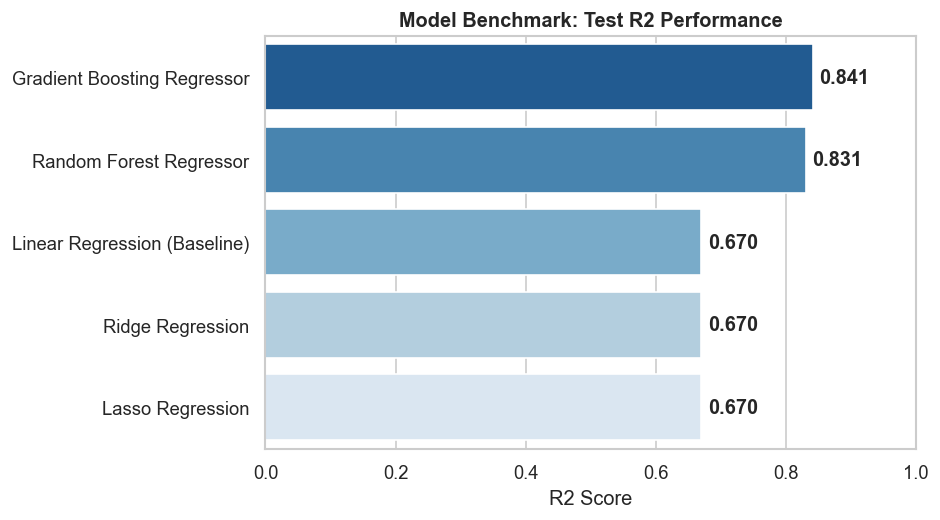

In [10]:
plt.figure(figsize=(8, 4.5))
sns.barplot(x='Test R2', y='Model', data=results_df, palette='Blues_r', hue='Model', legend=False)
plt.title('Model Benchmark: Test R2 Performance', weight='bold')
plt.xlabel('R2 Score')
plt.ylabel('')
plt.xlim(0, 1.0)
for i, r2_val in enumerate(results_df['Test R2']):
    plt.text(r2_val + 0.01, i, f"{r2_val:.3f}", va='center', weight='bold')
plt.tight_layout()
plt.show()

## 6. Model Diagnostics & Error Analysis

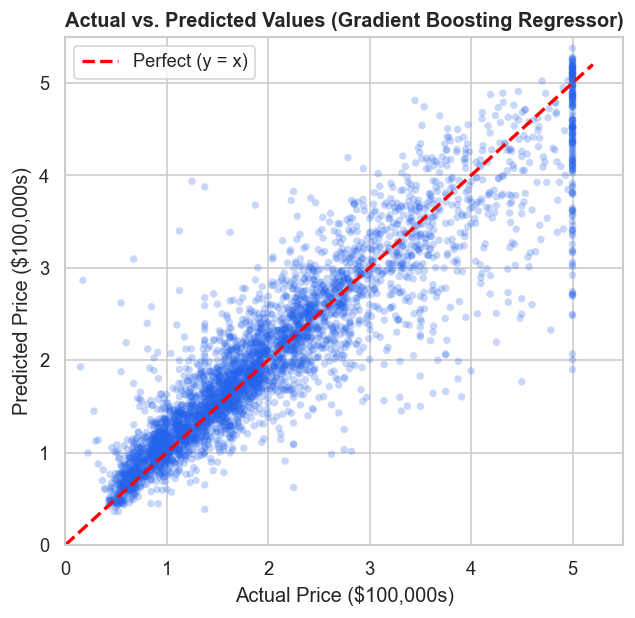

In [11]:
best_name = results_df.iloc[0]['Model']
best_pipe = trained_pipes[best_name]['pipe']
y_pred_best = trained_pipes[best_name]['y_pred']

# Actual vs Predicted Plot
plt.figure(figsize=(6, 5.5))
plt.scatter(y_test, y_pred_best, alpha=0.25, color='#2563EB', s=20, edgecolors='none')
plt.plot([0, 5.2], [0, 5.2], color='red', linestyle='--', lw=2, label='Perfect (y = x)')
plt.title(f'Actual vs. Predicted Values ({best_name})', weight='bold')
plt.xlabel('Actual Price ($100,000s)')
plt.ylabel('Predicted Price ($100,000s)')
plt.xlim(0, 5.5)
plt.ylim(0, 5.5)
plt.legend()
plt.show()

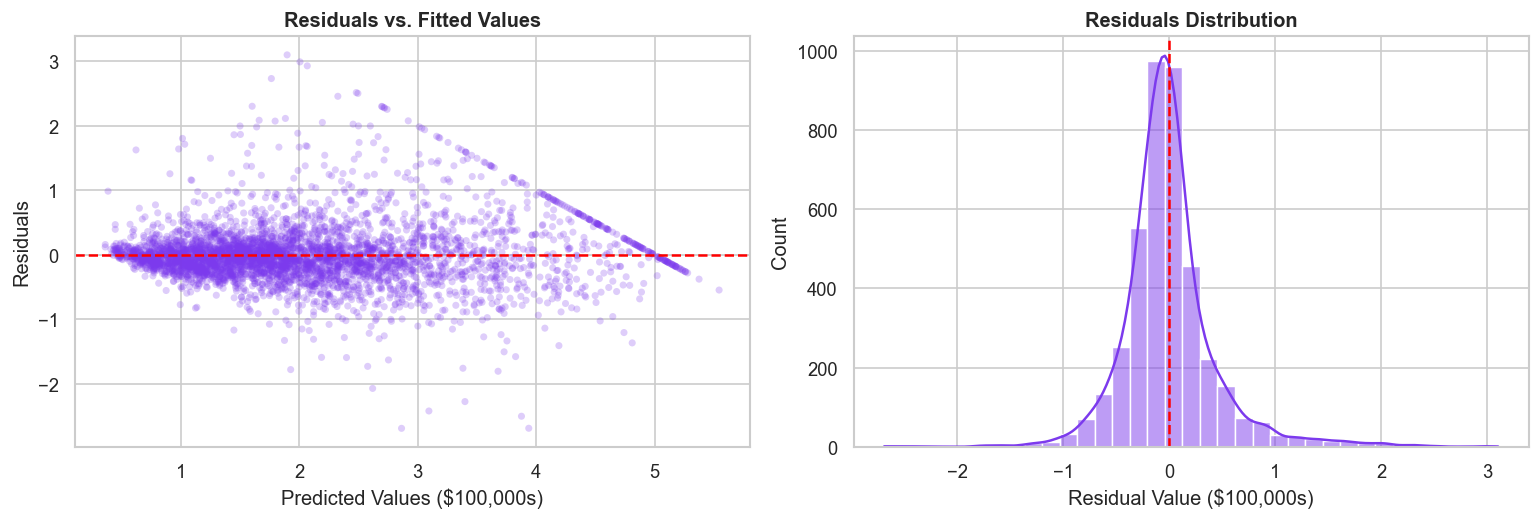

In [12]:
# Residual Diagnostics
residuals = y_test - y_pred_best
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(y_pred_best, residuals, alpha=0.25, color='#7C3AED', s=18, edgecolors='none')
axes[0].axhline(0, color='red', linestyle='--', lw=1.5)
axes[0].set_title('Residuals vs. Fitted Values', weight='bold')
axes[0].set_xlabel('Predicted Values ($100,000s)')
axes[0].set_ylabel('Residuals')

sns.histplot(residuals, kde=True, ax=axes[1], color='#7C3AED', bins=35)
axes[1].axvline(0, color='red', linestyle='--', lw=1.5)
axes[1].set_title('Residuals Distribution', weight='bold')
axes[1].set_xlabel('Residual Value ($100,000s)')
plt.tight_layout()
plt.show()

## 7. Feature Importance

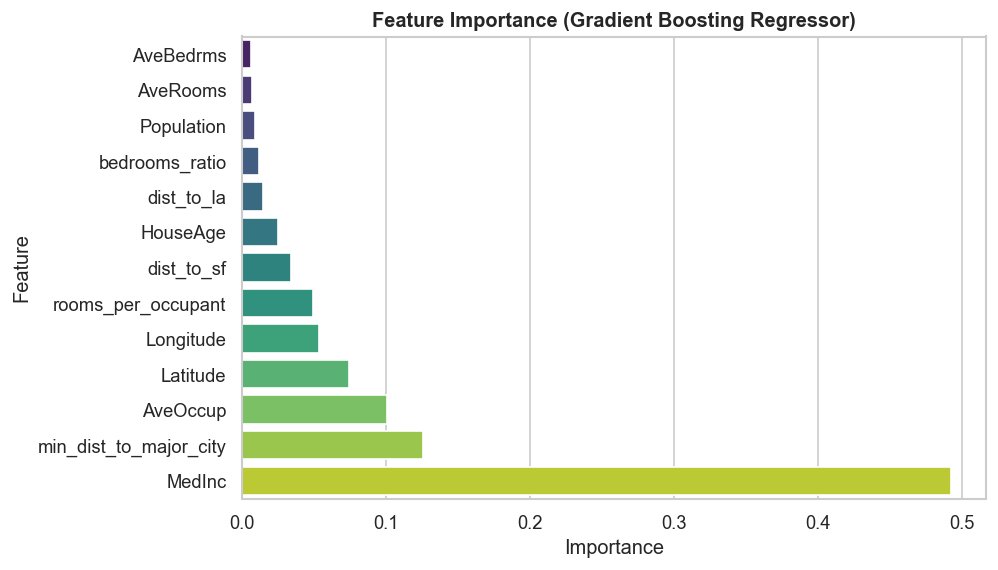

In [13]:
regressor = best_pipe.named_steps['regressor']
feat_eng = best_pipe.named_steps['feat_eng']
feature_names = feat_eng.get_feature_names_out()

if hasattr(regressor, 'feature_importances_'):
    importances = regressor.feature_importances_
    feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances}).sort_values('Importance', ascending=True)
    
    plt.figure(figsize=(8, 5))
    sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis', hue='Feature', legend=False)
    plt.title(f'Feature Importance ({best_name})', weight='bold')
    plt.xlabel('Importance')
    plt.show()

## 8. Model Serialization & Inference Verification

In [14]:
out_model_path = os.path.join(proj_root, 'outputs', 'best_house_price_pipeline.joblib')
joblib.dump(best_pipe, out_model_path)
print(f"Pipeline saved to: {out_model_path}")

# Verify reload and prediction
loaded_model = joblib.load(out_model_path)
sample_input = pd.DataFrame([{
    'MedInc': 4.5,
    'HouseAge': 25.0,
    'AveRooms': 5.5,
    'AveBedrms': 1.1,
    'Population': 1200.0,
    'AveOccup': 2.8,
    'Latitude': 37.88,
    'Longitude': -122.23
}])
pred_val = float(loaded_model.predict(sample_input)[0])
print(f"Test Sample Predicted Value: ${pred_val * 100000:,.2f} (Index: {pred_val:.4f})")

Pipeline saved to: F:\Projects\Qskill\qskill-ml-internship\house-price-prediction\outputs\best_house_price_pipeline.joblib
Test Sample Predicted Value: $203,583.15 (Index: 2.0358)
